<a href="https://colab.research.google.com/github/RiyaMahajan4/fraudshield-ai/blob/main/notebooks/03_baseline_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Baseline Machine Learning — FraudShield AI
Objective

Prepare transaction data using stratified splitting and leakage-safe preprocessing, train a Logistic Regression baseline, and evaluate fraud detection performance.

**Primary evaluation metric:** Average Precision (AP), summarizing precision-recall performance on this imbalanced dataset.

In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/creditcard.csv")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df["Class"].value_counts())

Dataset shape: (284807, 31)
Missing values: 0
Class
0    284315
1       492
Name: count, dtype: int64


In [4]:
# X contains the information used for prediction
X = df.drop(columns=["Class"])

# y contains the correct answer: 0 or 1
y = df["Class"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (284807, 30)
Target shape: (284807,)


In [5]:
from sklearn.model_selection import train_test_split

# First: reserve 15% for final testing
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

# Next: reserve 15% of the original dataset
# for validation (15/85 of the remaining data)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=15/85,
    stratify=y_temp,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nFraud percentages:")
print("Training:", round(y_train.mean() * 100, 4))
print("Validation:", round(y_val.mean() * 100, 4))
print("Testing:", round(y_test.mean() * 100, 4))

Training: (199364, 30)
Validation: (42721, 30)
Testing: (42722, 30)

Fraud percentages:
Training: 0.1725
Validation: 0.1732
Testing: 0.1732


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Features to scale
numeric_features = ["Time", "Amount"]

# Build preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), numeric_features)
    ],
    remainder="passthrough"
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and ML model
baseline_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

print("Baseline ML pipeline created!")

Baseline ML pipeline created!


In [8]:
# Train using training data only
baseline_pipeline.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Baseline Model Evaluation

Evaluate Logistic Regression on the validation set using classification metrics and a confusion matrix. The test set remains reserved for final evaluation.

In [9]:
# Predict transaction classes
y_val_pred = baseline_pipeline.predict(X_val)

# Predict fraud probabilities
y_val_prob = baseline_pipeline.predict_proba(X_val)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_pred), 4))
print("F1 Score:", round(f1_score(y_val, y_val_pred), 4))
print("Average Precision:", round(average_precision_score(y_val, y_val_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob), 4))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

Accuracy: 0.9992
Precision: 0.88
Recall: 0.5946
F1 Score: 0.7097
Average Precision: 0.7705
ROC-AUC: 0.9863

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42647
           1       0.88      0.59      0.71        74

    accuracy                           1.00     42721
   macro avg       0.94      0.80      0.85     42721
weighted avg       1.00      1.00      1.00     42721



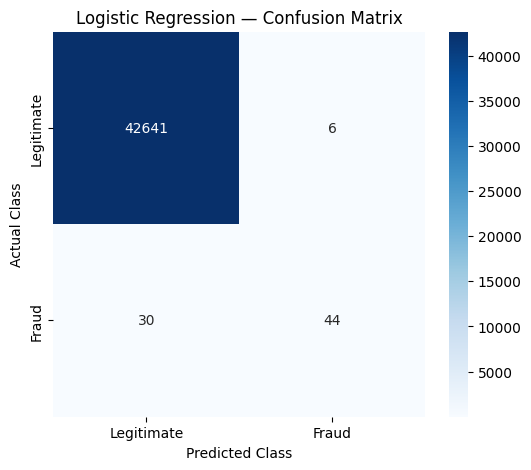

In [11]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Logistic Regression — Confusion Matrix")

plt.show()

Baseline Model Findings

- Logistic Regression achieved **99.92% accuracy**, but accuracy is less informative due to severe class imbalance.
- The model achieved **88% precision** and **59.46% recall**.
- Of 74 fraudulent transactions, **44 were detected and 30 were missed**, with only 6 false alarms.
- Average Precision was **0.7705**, providing a baseline for future model comparisons.

**Next step:** Investigate class imbalance handling and decision-threshold optimization to improve fraud recall while monitoring false positives.

Class-Weighted Logistic Regression

Train a second Logistic Regression model using balanced class weights to investigate whether emphasizing rare fraud cases improves recall.

In [12]:
# Create a new model with balanced class weights
weighted_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Train the new model
weighted_pipeline.fit(X_train, y_train)

print("Class-weighted model trained successfully!")

Class-weighted model trained successfully!


In [13]:
# Predictions on validation data
y_weighted_pred = weighted_pipeline.predict(X_val)
y_weighted_prob = weighted_pipeline.predict_proba(X_val)[:, 1]

# Calculate performance metrics
weighted_metrics = {
    "Accuracy": accuracy_score(y_val, y_weighted_pred),
    "Precision": precision_score(
        y_val, y_weighted_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, y_weighted_pred),
    "F1 Score": f1_score(y_val, y_weighted_pred),
    "Average Precision": average_precision_score(
        y_val, y_weighted_prob
    ),
    "ROC-AUC": roc_auc_score(y_val, y_weighted_prob)
}

print("Class-Weighted Logistic Regression Results:\n")

for metric, value in weighted_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_weighted_pred))

Class-Weighted Logistic Regression Results:

Accuracy: 0.9781
Precision: 0.0681
Recall: 0.9189
F1 Score: 0.1269
Average Precision: 0.7520
ROC-AUC: 0.9859

Confusion Matrix:
[[41717   930]
 [    6    68]]


In [14]:
baseline_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(
        y_val, y_val_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, y_val_pred),
    "F1 Score": f1_score(y_val, y_val_pred),
    "Average Precision": average_precision_score(
        y_val, y_val_prob
    ),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob)
}

comparison_df = pd.DataFrame({
    "Baseline": baseline_metrics,
    "Class Weighted": weighted_metrics
})

display(comparison_df.round(4))

,Baseline,Class Weighted
Accuracy,0.9992,0.9781
Precision,0.8800,0.0681
Recall,0.5946,0.9189
F1 Score,0.7097,0.1269
Average Precision,0.7705,0.7520
ROC-AUC,0.9863,0.9859


Class Weighting — Findings

- Fraud recall increased from **59.46% to 91.89%**.
- False positives increased significantly from **6 to 930**.
- Precision dropped from **88.00% to 6.81%**, while Average Precision decreased slightly from 0.7705 to 0.7520.
- Balanced class weighting improved fraud detection at the default threshold but introduced excessive false alarms.

Next experiment: Optimize the decision threshold to investigate a better precision-recall balance.

Decision Threshold Analysis

Evaluate different probability thresholds on the validation set to study the trade-off between fraud recall, precision, and false positives.

In [15]:
# Evaluate different thresholds for the original model
thresholds = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]

threshold_results = []

for threshold in thresholds:
    predictions = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Fraud Detected": tp,
        "Fraud Missed": fn,
        "False Positives": fp
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score,Fraud Detected,Fraud Missed,False Positives
0,0.05,0.7529,0.8649,0.8050,64,10,21
1,0.10,0.7922,0.8243,0.8079,61,13,16
2,0.20,0.7887,0.7568,0.7724,56,18,15
3,0.30,0.8154,0.7162,0.7626,53,21,12
4,0.40,0.8571,0.6486,0.7385,48,26,8
5,0.50,0.8800,0.5946,0.7097,44,30,6


Threshold Analysis — Findings

- Lowering the decision threshold improved fraud recall compared with the default threshold of 0.50.
- Among the six thresholds evaluated, **0.10 achieved the highest F1-score (0.8079)**, detecting 61 of 74 fraud cases with 16 false positives.
- A threshold of 0.05 achieved higher recall (86.49%) but produced more false positives.
- **0.10 is selected provisionally** for F1-based comparison on the validation set; final performance must be assessed on untouched test data.

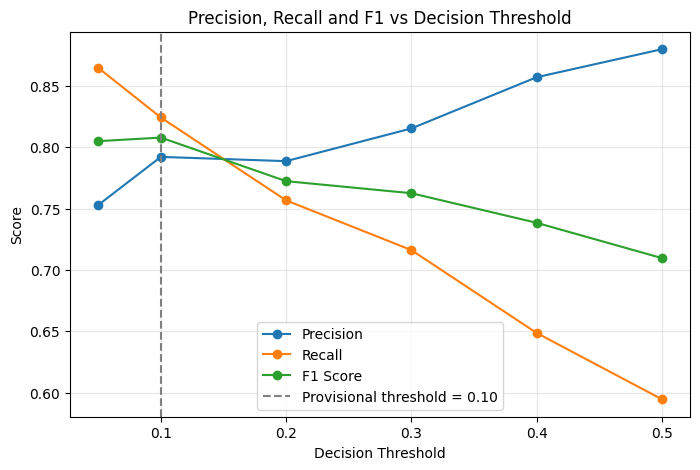

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.axvline(
    x=0.10,
    color="gray",
    linestyle="--",
    label="Provisional threshold = 0.10"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Decision Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

 Random Forest — Model Comparison

Train a Random Forest classifier and compare its validation performance with Logistic Regression.

In [21]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

random_forest_pipeline.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [22]:
rf_pred = random_forest_pipeline.predict(X_val)
rf_prob = random_forest_pipeline.predict_proba(X_val)[:, 1]

rf_metrics = {
    "Accuracy": accuracy_score(y_val, rf_pred),
    "Precision": precision_score(
        y_val, rf_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, rf_pred),
    "F1 Score": f1_score(y_val, rf_pred),
    "Average Precision": average_precision_score(
        y_val, rf_prob
    ),
    "ROC-AUC": roc_auc_score(y_val, rf_prob)
}

comparison_df = pd.DataFrame({
    "Logistic Regression": baseline_metrics,
    "Weighted Logistic": weighted_metrics,
    "Random Forest": rf_metrics
})

display(comparison_df.round(4))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(y_val, rf_pred))

,Logistic Regression,Weighted Logistic,Random Forest
Accuracy,0.9992,0.9781,0.9996
Precision,0.8800,0.0681,0.9365
Recall,0.5946,0.9189,0.7973
F1 Score,0.7097,0.1269,0.8613
Average Precision,0.7705,0.7520,0.8630
ROC-AUC,0.9863,0.9859,0.9884



Random Forest Confusion Matrix:
[[42643     4]
 [   15    59]]


Random Forest — Findings

- Random Forest achieved **93.65% precision**, **79.73% recall**, and an **F1-score of 0.8613**.
- It detected 59 of 74 fraud cases, missing 15 and generating only 4 false positives.
- Average Precision improved from 0.7705 (Logistic Regression) to 0.8630.
- Random Forest is currently the strongest model at the default decision threshold on the validation set.

Next: Evaluate Random Forest at different decision thresholds before selecting a final candidate.

In [23]:
rf_thresholds = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

rf_threshold_results = []

for threshold in rf_thresholds:
    predictions = (rf_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions
    ).ravel()

    rf_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Fraud Detected": tp,
        "Fraud Missed": fn,
        "False Positives": fp
    })

rf_threshold_df = pd.DataFrame(rf_threshold_results)

display(rf_threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score,Fraud Detected,Fraud Missed,False Positives
0,0.05,0.6701,0.8784,0.7602,65,9,32
1,0.10,0.7901,0.8649,0.8258,64,10,17
2,0.20,0.8421,0.8649,0.8533,64,10,12
3,0.30,0.8493,0.8378,0.8435,62,12,11
4,0.40,0.8939,0.7973,0.8429,59,15,7
5,0.50,0.9365,0.7973,0.8613,59,15,4
6,0.60,0.9508,0.7838,0.8593,58,16,3


Random Forest Threshold Findings

- Threshold **0.50** achieved the highest F1-score (0.8613) among the tested values, detecting 59 of 74 fraud cases with 4 false positives.
- Threshold **0.20** increased recall to 86.49%, detecting 64 fraud cases with 12 false positives.
- Lower thresholds improved fraud detection but increased false alarms.
- Threshold 0.50 remains the provisional F1-based choice; 0.20 is retained as a higher-recall alternative.

In [24]:
# Compare selected model configurations
model_summary = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Threshold": 0.50,
        "Precision": 0.8800,
        "Recall": 0.5946,
        "F1": 0.7097,
        "Fraud Detected": 44,
        "False Positives": 6
    },
    {
        "Model": "Logistic Regression (Tuned)",
        "Threshold": 0.10,
        "Precision": 0.7922,
        "Recall": 0.8243,
        "F1": 0.8079,
        "Fraud Detected": 61,
        "False Positives": 16
    },
    {
        "Model": "Random Forest",
        "Threshold": 0.50,
        "Precision": 0.9365,
        "Recall": 0.7973,
        "F1": 0.8613,
        "Fraud Detected": 59,
        "False Positives": 4
    },
    {
        "Model": "Random Forest (Higher Recall)",
        "Threshold": 0.20,
        "Precision": 0.8421,
        "Recall": 0.8649,
        "F1": 0.8533,
        "Fraud Detected": 64,
        "False Positives": 12
    }
])

display(model_summary)

,Model,Threshold,Precision,Recall,F1,Fraud Detected,False Positives
0,Logistic Regression,0.5,0.8800,0.5946,0.7097,44,6
1,Logistic Regression (Tuned),0.1,0.7922,0.8243,0.8079,61,16
2,Random Forest,0.5,0.9365,0.7973,0.8613,59,4
3,Random Forest (Higher Recall),0.2,0.8421,0.8649,0.8533,64,12


Cross-Validation

Evaluate model stability using stratified cross-validation on the training dataset. The original validation and test sets remain separate.

In [25]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "Average Precision": "average_precision",
        "F1": "f1",
        "Recall": "recall"
    },
    n_jobs=-1
)

cv_summary = pd.DataFrame({
    "Average Precision": cv_results["test_Average Precision"],
    "F1": cv_results["test_F1"],
    "Recall": cv_results["test_Recall"]
})

display(cv_summary.round(4))

print("\nMean Scores:")
print(cv_summary.mean().round(4))

print("\nStandard Deviation:")
print(cv_summary.std().round(4))

,Average Precision,F1,Recall
0,0.7687,0.785,0.7304
1,0.7777,0.750,0.6522
2,0.7603,0.709,0.5877



Mean Scores:
Average Precision    0.7689
F1                   0.7480
Recall               0.6568
dtype: float64

Standard Deviation:
Average Precision    0.0087
F1                   0.0381
Recall               0.0715
dtype: float64


Logistic Regression Cross-Validation Findings

- Three-fold stratified cross-validation produced a mean Average Precision of **0.7689**.
- Mean F1-score was **0.7480**, while mean recall was **65.68%**.
- Average Precision varied relatively little across folds, but recall showed greater variability.
- Further model comparison is needed to assess whether Random Forest provides more reliable fraud detection.

In [26]:
# Cross-validation for Random Forest
rf_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "Average Precision": "average_precision",
        "F1": "f1",
        "Recall": "recall"
    },
    n_jobs=1
)

rf_cv_summary = pd.DataFrame({
    "Average Precision": rf_cv_results["test_Average Precision"],
    "F1": rf_cv_results["test_F1"],
    "Recall": rf_cv_results["test_Recall"]
})

display(rf_cv_summary.round(4))

print("\nMean Scores:")
print(rf_cv_summary.mean().round(4))

print("\nStandard Deviation:")
print(rf_cv_summary.std().round(4))

,Average Precision,F1,Recall
0,0.8668,0.8558,0.7739
1,0.8225,0.8545,0.7913
2,0.8197,0.8200,0.7193



Mean Scores:
Average Precision    0.8364
F1                   0.8434
Recall               0.7615
dtype: float64

Standard Deviation:
Average Precision    0.0264
F1                   0.0203
Recall               0.0376
dtype: float64


Cross-Validation Comparison — Findings

- Random Forest achieved higher mean Average Precision (0.8364) than Logistic Regression (0.7689).
- Random Forest also achieved higher mean F1-score (0.8434) and recall (76.15%).
- Its F1-score and recall showed lower variability across the three folds.
- **Random Forest is selected as the leading model candidate**, subject to final evaluation on the untouched test set.

In [27]:
# Get feature importance from Random Forest
rf_model = random_forest_pipeline.named_steps["classifier"]

# Get feature names in the order used by the model
feature_names = (
    random_forest_pipeline
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

# Create feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Clean feature names
importance_df["Feature"] = (
    importance_df["Feature"]
    .str.replace("scaler__", "", regex=False)
    .str.replace("remainder__", "", regex=False)
)

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

display(importance_df.head(10))

,Feature,Importance
13,V12,0.191707
15,V14,0.174806
18,V17,0.139528
11,V10,0.068880
12,V11,0.067152
17,V16,0.052063
10,V9,0.037994
19,V18,0.037367
5,V4,0.031114
8,V7,0.026582


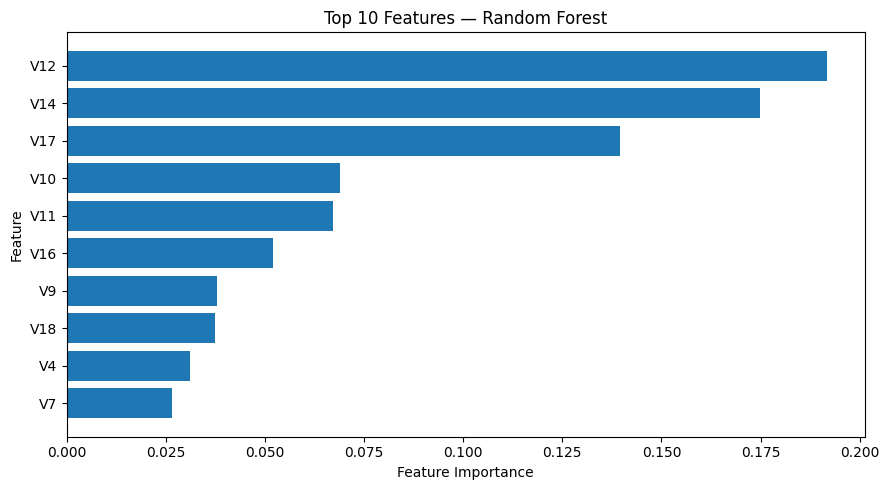

In [28]:
# Select top 10 important features
top_features = importance_df.head(10).sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features — Random Forest")

plt.tight_layout()
plt.show()

Feature Importance — Findings

- V12, V14, and V17 have the highest built-in Random Forest feature importance scores.
- These features also showed strong associations with fraud during exploratory analysis.
- Feature importance indicates how the trained trees used the features, not causal relationships.

**Next:** Validate feature importance using permutation importance on unseen validation data.

In [29]:
## Permutation Feature Importance

from sklearn.inspection import permutation_importance

# Use the full validation set to preserve rare fraud cases
perm_results = permutation_importance(
    random_forest_pipeline,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

perm_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_results.importances_mean
})

perm_df = perm_df.sort_values(
    "Importance", ascending=False
)

display(perm_df.head(10).round(4))

,Feature,Importance
14,V14,0.0794
12,V12,0.0680
4,V4,0.0210
17,V17,0.0156
10,V10,0.0134
9,V9,0.0131
11,V11,0.0115
28,V28,0.0088
16,V16,0.0077
26,V26,0.0064


Permutation Importance — Findings

- V14 and V12 produced the largest decreases in validation Average Precision when shuffled.
- V12, V14, and V17 ranked prominently in both importance methods.
- V4 ranked higher in permutation importance than in built-in Random Forest importance.
- The results support the relevance of these features but do not establish causal relationships.

Final Model Training

In [30]:
from sklearn.base import clone

# Combine training and validation data
X_final_train = pd.concat(
    [X_train, X_val],
    axis=0
)

y_final_train = pd.concat(
    [y_train, y_val],
    axis=0
)

# Create a fresh copy of the selected model
final_model = clone(random_forest_pipeline)

# Retrain using all available development data
final_model.fit(X_final_train, y_final_train)

print("Final Random Forest model trained!")
print("Training samples:", len(X_final_train))
print("Reserved test samples:", len(X_test))

Final Random Forest model trained!
Training samples: 242085
Reserved test samples: 42722


Final Test Evaluation

In [31]:
# Final predictions on untouched test data
y_test_pred = final_model.predict(X_test)
y_test_prob = final_model.predict_proba(X_test)[:, 1]

# Calculate final evaluation metrics
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test, y_test_pred, zero_division=0
    ),
    "Recall": recall_score(y_test, y_test_pred),
    "F1 Score": f1_score(y_test, y_test_pred),
    "Average Precision": average_precision_score(
        y_test, y_test_prob
    ),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob)
}

print("FINAL RANDOM FOREST TEST RESULTS\n")

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))


FINAL RANDOM FOREST TEST RESULTS

Accuracy: 0.9996
Precision: 0.9516
Recall: 0.7973
F1 Score: 0.8676
Average Precision: 0.8179
ROC-AUC: 0.9706

Confusion Matrix:
[[42645     3]
 [   15    59]]


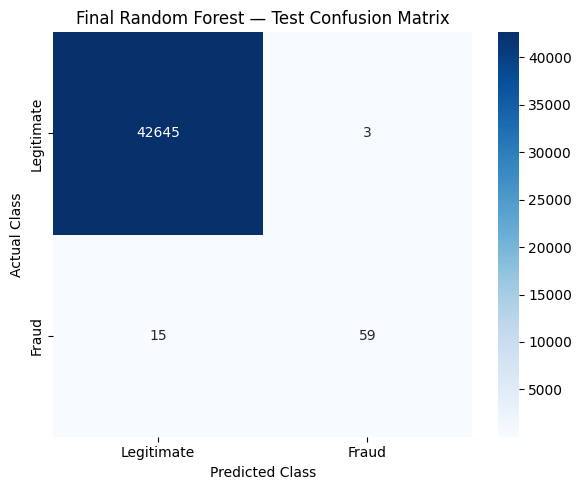

In [32]:
final_cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Final Random Forest — Test Confusion Matrix")

plt.tight_layout()
plt.show()

Final Test Evaluation — Findings

- The final Random Forest achieved **95.16% precision**, **79.73% recall**, and an **F1-score of 0.8676** on 42,722 unseen test transactions.
- It correctly identified **59 of 74 fraud cases**, missed 15, and generated only 3 false positives.
- Average Precision was **0.8179**, compared with 0.8630 on the validation set.
- The model demonstrated promising fraud detection performance, although missed fraud cases and generalization to future transactions remain important limitations.

Save Final Model

In [33]:
import joblib
import os

# Create a folder for trained models
os.makedirs("models", exist_ok=True)

# Save the complete preprocessing + model pipeline
model_path = "models/fraudshield_random_forest.joblib"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)
print("File size (MB):", round(
    os.path.getsize(model_path) / (1024 ** 2), 2
))

Model saved successfully!
Location: models/fraudshield_random_forest.joblib
File size (MB): 1.16


In [34]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Compare predictions from original and loaded models
original_predictions = final_model.predict(X_test.head(10))
loaded_predictions = loaded_model.predict(X_test.head(10))

print(
    "Predictions match:",
    np.array_equal(
        original_predictions,
        loaded_predictions
    )
)

Predictions match: True


In [35]:
# Check the input columns expected by our model
expected_features = list(final_model.feature_names_in_)

print("Number of input features:", len(expected_features))
print("\nExpected features:")
print(expected_features)

Number of input features: 30

Expected features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [36]:
import sys
import sklearn
import joblib

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Scikit-learn: 1.6.1
Joblib: 1.6.0


In [37]:
# Create a small test dataset
sample_data = df.sample(n=100, random_state=42)

# Save it as a CSV file
sample_data.to_csv("fraudshield_test.csv", index=False)

# Download the CSV
from google.colab import files
files.download("fraudshield_test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
# Create a CSV with missing required features
invalid_data = df[["Time", "Amount"]].head(5)

invalid_data.to_csv(
    "test_missing_columns.csv",
    index=False
)

from google.colab import files
files.download("test_missing_columns.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
# Select 5 transactions
invalid_data = df.head(5).copy()

# Replace a numerical value with text
invalid_data.loc[0, "Amount"] = "invalid"

# Save the test file
invalid_data.to_csv(
    "test_invalid_values.csv",
    index=False
)

# Download it
from google.colab import files
files.download("test_invalid_values.csv")

/tmp/ipykernel_1651/3725919434.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'invalid' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  invalid_data.loc[0, "Amount"] = "invalid"


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
# Create a CSV with column names but no transactions
empty_data = df.head(0)

# Save the empty dataset
empty_data.to_csv("test_empty.csv", index=False)

# Download the file
from google.colab import files
files.download("test_empty.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>